# Error mitigation with zero-noise extrapolation

## The problem

A noisy device returns the wrong answer, and the error grows with the length of the circuit. Take a circuit whose correct value we can work out on paper. A noiseless computer would return that value. A real device returns a smaller one, and a longer circuit returns a smaller one still.

The value in question is an **expectation value** $\langle O\rangle$ (the number the Estimator returns): the average of the $\pm1$ answer of an observable $O$ over many runs. Noise pulls $\langle O\rangle$ toward $0$, the average of a fair coin flip. We use these names:

- the **ideal value** is what a noiseless computer returns;
- the **unmitigated value** is what the device returns when we do nothing about the noise;
- the **bias** of an estimate is its average over many repeated runs, minus the ideal value;
- the **spread** of an estimate is its standard deviation over many repeated runs (the typical distance of one run from the average of the runs).

**Error mitigation** is a set of methods that estimate the ideal value from noisy runs. An estimate made this way is a **mitigated value**. Mitigation needs no extra qubits. It costs more runs and more computing afterward. This notebook covers one method.

**The idea.** We cannot switch the noise off, but we can turn it up. Let the **noise factor** $\lambda$ say how much noise a circuit has: $\lambda = 1$ is the circuit on the device as it is, and $\lambda = 3$ is a circuit that has three times as much noise. We measure $\langle O\rangle$ at $\lambda = 1, 3, 5$, plot the three values against $\lambda$, fit a curve through them, and read the curve at $\lambda = 0$. That reading is the mitigated value. The method is called **zero-noise extrapolation** (ZNE), because it extends the data past the measured range to the point with no noise.

**How to turn the noise up.** A gate $G$ followed by its **inverse** $G^\dagger$ (the gate that undoes $G$) does nothing. So the three gates $G\,G^\dagger\,G$ do the same as the single gate $G$, and the device runs three gates instead of one. This is **gate folding**. If each gate keeps a fraction $1-\varepsilon$ of the signal, one gate leaves $1-\varepsilon$ and the folded three leave $(1-\varepsilon)^3 \approx 1 - 3\varepsilon$. The loss is three times as large, to first order in the small error $\varepsilon$. Step 1 makes this exact for our test circuit.

**What it costs.** The fit can be wrong (a straight line through a curve misses), which leaves a bias. And the measured values carry random error, which the extrapolation amplifies, so the spread grows. The notebook measures both.

## The workflow

| Step | What it does | Code |
|---|---|---|
| 1. Operator | The observable, the ideal value, the noise of the simulator, and the fit models | `ops.py` |
| 2. Encoding | Build the test circuit, fold it to each noise factor, and compile it | `encoding.py` |
| 3. Execution | Run every circuit at every noise factor as one job | `execution.py` |
| 4. Analysis | Extrapolate to zero noise, compare with the ideal, weigh the cost | `analysis.py` |

The same steps run from the command line with `python zero_noise_extrapolation/main.py`, started in `../scripts/`. The code lives in `../scripts/zero_noise_extrapolation/` and is imported below.

## Setup

By default the notebook runs on **Aer**, Qiskit's simulator that runs on your computer, with a depolarizing error on every CX gate: with probability $p = 1\%$ the state of the two qubits is replaced by a random one. Step 1 shows how that gives the factor $1-p$ per gate that you know from the benchmarking notebooks. Because we chose the noise, we know the exact noisy value at every noise factor and can check every step. Set `backend_name = "ibm_rensselaer"` to run on hardware. The hardware path has not been tested.

The code is in four modules, imported below.

- `ops.py` holds the observable, the ideal and exact values, and the fit models.
- `encoding.py` builds, folds, and compiles circuits. `execution.py` runs them on the Estimator.
- `analysis.py` fits the data and draws the figures.

The settings:

- `qubits`: the two physical qubits to use on hardware. They must be connected. Ignored on the simulator.
- `n_cx`: number of CX gates in the circuit. Keep it even (Step 1 explains why).
- `measured`: the noise factors to measure. The fits use the subset `use`.
- `repeats`: how many times the whole measurement is repeated, to see the spread of each estimate. The simulator only; hardware runs once, and the cells that need repeats are skipped.
- `precision`: target **standard error** of each expectation value, the typical size of its random error. A measurement made of $S$ **shots** (repetitions of the circuit, each giving one $\pm1$ answer) has a standard error of at most $1/\sqrt S$. On hardware, `precision` therefore sets the number of shots, about $1/\text{precision}^2$. The simulator adds random noise of that size to the exact value.
- `depths`: circuit lengths for the sweep at the end.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from qiskit.quantum_info import Statevector

# The ZNE code lives in ../scripts/zero_noise_extrapolation.
# Run this notebook from its own folder (the Jupyter default).
sys.path.insert(0, str(Path("../scripts/zero_noise_extrapolation").resolve()))

import analysis
import encoding as enc
import execution
import ops

%matplotlib inline

backend_name = None  # None = Aer simulator, or e.g. "ibm_rensselaer"
qubits = [0, 1]  # physical qubits, hardware only
n_cx = 20
measured = (1, 2, 3, 4, 5)
use = (1, 3, 5)
repeats = 500
precision = 0.02
depths = (4, 10, 20, 30, 40)
simulated = backend_name is None

## Step 1: The operator (what we measure and what we fit)

### The observable and the circuit

Reading a qubit gives the bit 0 or 1. The observable $Z$ assigns the number $+1$ to the bit 0 and $-1$ to the bit 1. The observable $ZZ$ reads both qubits and multiplies the two numbers: the product is $+1$ if the two bits agree (00 or 11) and $-1$ if they differ (01 or 10). So $\langle ZZ\rangle = P(\text{agree}) - P(\text{differ})$.

The test circuit has two qubits, both starting at 0.

1. $R_Y(\theta)$ on qubit 0, the rotation gate of Unit 1. It turns the state 0 into $\cos(\theta/2)\,\lvert 0\rangle + \sin(\theta/2)\,\lvert 1\rangle$. The probability of an outcome is the square of its amplitude, so qubit 0 reads 0 with probability $\cos^2(\theta/2)$ and 1 with probability $\sin^2(\theta/2)$.
2. A string of $N$ CX gates, each with qubit 0 as control and qubit 1 as target. A CX flips qubit 1 if qubit 0 reads 1. As a matrix, CX multiplied by itself is the identity, so two CX gates in a row leave every state unchanged, including a state in which qubit 0 is a superposition.

With $N$ even the CX gates cancel in pairs and the circuit ideally does only the first step. Every effect of the CX gates on the result is then noise, and $N$ sets how much.

**Worked example: the ideal value.** Take $\theta = 60^\circ$ and $N = 20$.

**Problem.** What is $\langle ZZ\rangle$ of the ideal circuit?

**Plan.** Find the state before the CX gates, check that they leave it unchanged, then average the product of the two numbers.

**Solution.**

**Subgoal 1: the state after the rotation.**

1. Qubit 0 reads 0 with probability $\cos^2 30^\circ = 0.75$ and 1 with probability $\sin^2 30^\circ = 0.25$. Qubit 1 reads 0.

**Subgoal 2: the CX gates.**

2. The 20 CX gates are 10 pairs. Each pair is the identity matrix, so the state is unchanged. Qubit 1 still reads 0.

**Subgoal 3: the average.**

3. Qubit 1 reads 0, which counts as $+1$, so the product is the number of qubit 0: $+1$ with probability 0.75 and $-1$ with probability 0.25.
4. $\langle ZZ\rangle = 0.75 - 0.25 = 0.5$.

**Check.** The general result is $\cos^2(\theta/2) - \sin^2(\theta/2) = \cos\theta$, and $\cos 60^\circ = 0.5$. The code below checks it on a noiseless statevector for several $N$.

In [2]:
obs = ops.observable()
print(f"ideal value cos(theta) = {ops.ideal_value():.4f}\n")
print(f"{'N':>3} {'<ZZ> (noiseless)':>18}")
for n in (0, 1, 2, 20):
    value = Statevector(enc.build_circuit(n)).expectation_value(obs).real
    print(f"{n:>3} {value:>18.4f}")

ideal value cos(theta) = 0.5000

  N   <ZZ> (noiseless)
  0             0.5000
  1             1.0000
  2             0.5000
 20             0.5000


For $N = 0, 2, 20$ the value is $0.5$. For $N = 1$ it is $1$: a single CX copies the bit of qubit 0 onto qubit 1, so the two always agree. That is why $N$ must be even.

### The noise: a depolarizing error on each CX

The simulator applies a **depolarizing error** with probability $p = 0.01$ after every CX: with probability $p$ the state of the two qubits is replaced by a random state, in which the four bit pairs 00, 01, 10, 11 are equally likely. In a random state the two bits agree half the time, so $\langle ZZ\rangle = 0$.

Follow the $N$ CX gates of the circuit.

- With probability $(1-p)^N$ none of them has an error, and the circuit gives its ideal value $\cos\theta$.
- Otherwise an error replaced the state by a random one at some gate. A CX only swaps which bit pair is which, so it turns a random state into a random state, and no later gate can bring the signal back. The value is $0$.

The average is $\langle ZZ\rangle = (1-p)^N\cos\theta + \left[1-(1-p)^N\right]\times 0$. Each gate therefore multiplies the signal by $1-p$, the rule from the benchmarking notebooks. A circuit with noise factor $\lambda$ has $N\lambda$ CX gates, so

$$\langle ZZ\rangle(\lambda) = (1-p)^{N\lambda}\cos\theta = \cos\theta\; e^{-b\lambda}, \qquad b = -N\ln(1-p).$$

The second form follows from $(1-p)^{N\lambda} = e^{N\lambda\ln(1-p)}$. The constant $b$ is the **decay rate** of the curve. Noise factor $0$ gives the ideal value $\cos\theta$. We define the noise factor by the gate count, which makes this exact. The three folded gates of one CX leave $(1-p)^3 = 0.9703$ of the signal, compared with $0.99$ for one gate. The loss is $0.0297$, which is $2.97$ times the single-gate loss of $0.01$: three times to first order in $p$.

**Worked example: the noisy values.** With $N = 20$ and $p = 0.01$:

1. $\lambda = 1$: $0.99^{20} = 0.8179$, so $\langle ZZ\rangle = 0.8179 \times 0.5 = 0.4090$.
2. $\lambda = 3$: $0.99^{60} = 0.5472$, so $\langle ZZ\rangle = 0.2736$.
3. $\lambda = 5$: $0.99^{100} = 0.3660$, so $\langle ZZ\rangle = 0.1830$.

**Check.** The decay rate is $b = -20\ln 0.99 = 0.2010$, and $e^{-0.2010} = 0.8179$, which matches step 1.

The table shows the problem: the same circuit, the same ideal value, and a loss that grows with the number of gates. The column "lost" is the fraction of the ideal value that is missing, $1 - \text{value}/\text{ideal}$.

In [3]:
print(f"ideal value: {ops.ideal_value():.4f}")
print(f"{'N':>4} {'exact noisy <ZZ>':>18} {'lost':>8}")
for n in (0, 10, 20, 40, 80):
    value = ops.exact_value(n)
    print(f"{n:>4} {value:>18.4f} {1 - value / ops.ideal_value():>8.1%}")

ideal value: 0.5000
   N   exact noisy <ZZ>     lost
   0             0.5000     0.0%
  10             0.4522     9.6%
  20             0.4090    18.2%
  40             0.3345    33.1%
  80             0.2238    55.2%


### The fit models

A fit chooses the parameters of a model so that the curve follows the data. With more points than parameters the curve cannot pass through every point, so we use **least squares**: choose the parameters that minimize the sum of the squared differences between model and data. The SciPy function `curve_fit` does this. We fit three models to $\langle ZZ\rangle(\lambda)$ and evaluate each at $\lambda = 0$.

| Extrapolator | Model | Value at $\lambda=0$ |
|---|---|---|
| Linear | $c_0 + c_1\lambda$ | $c_0$ |
| Quadratic | $c_0 + c_1\lambda + c_2\lambda^2$ | $c_0$ |
| Exponential | $a\,e^{-b\lambda}$ | $a$ |

An **extrapolator** is a model used this way. The quadratic model has three parameters, so with exactly three noise factors it is the one parabola that passes through all three points. This case is called **Richardson extrapolation**. The exponential model has no offset, because the noisy value falls toward $0$ (the value of a random state) as $\lambda$ grows.

**Worked example: Richardson by hand.** Use the exact values at $\lambda = 1, 3, 5$ from above: $0.4090$, $0.2736$, $0.1830$.

**Problem.** Find the value at $\lambda = 0$ of the parabola through the three points.

**Plan.** Write the parabola as a weighted sum of the three values (the **Lagrange form**: a polynomial through points written as a sum of the $y$ values times weights), compute the weights, and combine.

**Solution.**

**Subgoal 1: the weights.**

1. The value at $0$ of the parabola through the points $(x_i, y_i)$ is $\sum_i c_i y_i$ with $c_i = \prod_{j\ne i} \dfrac{0 - x_j}{x_i - x_j}$. Each weight $c_i$ is 1 at its own point and 0 at the others, which makes the sum pass through every point.
2. For $x = (1, 3, 5)$: $c_1 = \dfrac{(-3)(-5)}{(1-3)(1-5)} = \dfrac{15}{8}$, $c_3 = \dfrac{(-1)(-5)}{(3-1)(3-5)} = -\dfrac{5}{4}$, $c_5 = \dfrac{(-1)(-3)}{(5-1)(5-3)} = \dfrac{3}{8}$.

**Subgoal 2: the value.**

3. $1.875 \times 0.4090 - 1.25 \times 0.2736 + 0.375 \times 0.1830 = 0.7668 - 0.3420 + 0.0686 = 0.4934$.

**Check.** The weights add to $1.875 - 1.25 + 0.375 = 1$, so data that is constant at $y$ would extrapolate to $y$, as it should. The result, $0.4934$, is close to the ideal $0.5$ but not equal, because the exact curve is an exponential and not a parabola. The bias is about $-0.007$.

The code below does the same fit for all three models with `curve_fit`, on the exact values.

In [4]:
exact = [ops.exact_value(n_cx, f) for f in use]
print("exact values at", use, "->", np.round(exact, 4))
print(f"{'':<24} {'value at 0':>10} {'bias':>8}")
for method in ops.METHODS:
    value = analysis.extrapolate(method, use, exact)
    print(f"{ops.NAMES[method]:<24} {value:>10.4f} {value - ops.ideal_value():>+8.4f}")
print("\nRichardson weights:", analysis.weights("quadratic", use))

exact values at (1, 3, 5) -> [0.409  0.2736 0.183 ]
                         value at 0     bias
Linear                       0.4580  -0.0420
Quadratic (Richardson)       0.4934  -0.0066
Exponential                  0.5000  +0.0000

Richardson weights: [ 1.875 -1.25   0.375]


With noise-free data the exponential returns $0.5000$, because the data are exactly exponential. The linear fit is off by about $-0.04$ and the parabola by about $-0.007$. These are the biases of the models, before any measurement error enters.

## Stop and think: what is the model assuming?

1. **Why is the exponential exact here?** Each CX multiplies $\langle ZZ\rangle$ by $0.99$ on average, so $N\lambda$ gates multiply it by $0.99^{N\lambda}$, which is an exponential in $\lambda$. We built the noise that way. The noise of a real gate may follow another law, and then the exponential model is biased too. Comparing the extrapolators on the data is how we judge.
2. **Which errors does gate folding amplify?** Those that grow with the number of CX gates. **Read-out error** (the device reports the wrong bit when it measures) happens once per run, whatever the circuit. It stays at the same size in every point of the curve and stays in the extrapolated value. Read-out error needs its own mitigation.
3. **Why can the data not tell the models apart?** Three different curves can pass near the same three points and disagree at $0$. The data constrain the curve only where we measured. The choice of model is an assumption about the noise.

## Step 2: Encoding

### The circuit and its folds

Four functions of `encoding.py` do the work.

| Function | What it does |
|---|---|
| `build_circuit(n)` | Makes the circuit of Step 1 with $n$ CX gates. |
| `fold_gates(circuit, factor)` | Folds the two-qubit gates, $G \to G\,G^\dagger\,G$, to reach the noise factor. |
| `fold_circuit(circuit, factor)` | Folds the whole circuit, $U \to U\,U^\dagger\,U$. |
| `transpile_for(circuit, backend)` | **Compiles** the circuit for a device: rewrites it in the gates the device supports, with no shortening (explained below). |

In `fold_gates` each CX becomes three. A CX is its own inverse, so $G\,G^\dagger\,G$ is three CX in a row. Two-qubit gates are the noisiest, and they are the ones IBM hardware folds too.

Each fold adds two gates, so a noise factor between 1 and 3 folds a fraction of the gates. A factor of 2 on 20 gates folds 10 of them: $20 + 2 \times 10 = 40 = 2 \times 20$. Larger factors fold some gates more than once.

In `fold_circuit`, $U^\dagger$ is the circuit with its gates in reverse order and each one inverted. It needs an odd factor.

The four drawings are a circuit with two CX gates (`CX` is the dot-and-plus symbol) and three folded versions of it, each printed with its CX count and its ideal $\langle ZZ\rangle$ from a noiseless statevector.

original: 2 CX, ideal <ZZ> = 0.5000


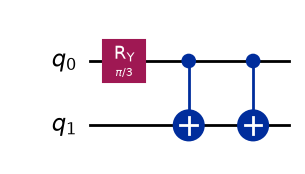

gate folding, factor 2: 4 CX, ideal <ZZ> = 0.5000


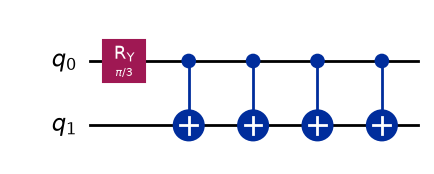

gate folding, factor 3: 6 CX, ideal <ZZ> = 0.5000


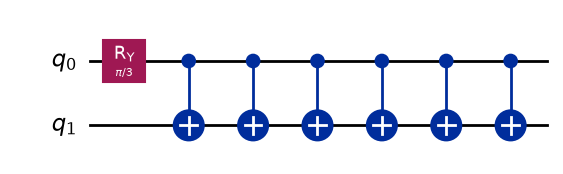

whole circuit folding, factor 3: 6 CX, ideal <ZZ> = 0.5000


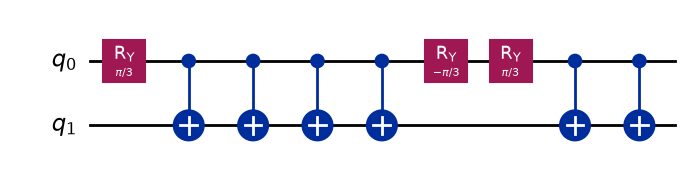

In [5]:
small = enc.build_circuit(2)
variants = [
    ("original", small),
    ("gate folding, factor 2", enc.fold_gates(small, 2)),
    ("gate folding, factor 3", enc.fold_gates(small, 3)),
    ("whole circuit folding, factor 3", enc.fold_circuit(small, 3)),
]
for label, circuit in variants:
    ideal = Statevector(circuit).expectation_value(obs).real
    print(f"{label}: {circuit.count_ops().get('cx', 0)} CX, ideal <ZZ> = {ideal:.4f}")
    fig = circuit.draw("mpl")
    display(fig)
    plt.close(fig)  # keep the inline backend from drawing it a second time

Every variant has the same ideal value, $0.5$. The CX counts are 2, 4, 6, and 6. In the whole-circuit fold the rotation is folded too, so $R_Y(\theta)$ is followed by $R_Y(-\theta)$ and $R_Y(\theta)$ again. On the simulator only CX gates carry noise, so the two folds at factor 3 give the same noisy value. On hardware the single-qubit gates have small errors of their own.

The next table runs the same check on the real circuit at every noise factor we will measure.

In [6]:
base = enc.build_circuit(n_cx)
print(
    f"{'factor':>6} {'requested CX':>13} {'CX in folded circuit':>21} {'ideal <ZZ>':>11}"
)
for f in measured:
    folded = enc.fold_gates(base, f)
    ideal = Statevector(folded).expectation_value(obs).real
    print(f"{f:>6} {f * n_cx:>13} {folded.count_ops()['cx']:>21} {ideal:>11.4f}")

factor  requested CX  CX in folded circuit  ideal <ZZ>
     1            20                    20      0.5000
     2            40                    40      0.5000
     3            60                    60      0.5000
     4            80                    80      0.5000
     5           100                   100      0.5000


## Stop and think: what did the encoding decide?

1. **What changes under folding, and what stays the same?** The number of CX gates is multiplied by the noise factor, and the ideal $\langle ZZ\rangle$ stays at $0.5$. That is the property we need: every circuit has the same ideal answer, so any change in the measured value is noise.
2. **Why must the compiler not shorten the circuit?** Before a circuit runs, Qiskit compiles it. Compiling rewrites it in the gates the device supports, and at a higher **optimization level** it also shortens it by removing gates that cancel. A CX followed by a CX cancels, so the optimizer would delete every fold and each noise factor would compile back to the original circuit. The curve would be flat. `transpile_for` uses optimization level 0, which does no shortening.
3. **Why must a noise factor be at least 1?** Folding only adds gates. A circuit with noise factor $0$ would need fewer gates than the original, and removing gates changes the answer: a circuit with one CX has ideal value $1$ and a circuit with none has $0.5$. So we cannot measure $\lambda = 0$, and we extrapolate to it.
4. **Which factors fold every gate equally?** The odd ones. The factors 1, 3, 5 give each gate 0, 1, 2 folds. A factor like 2 folds half of the gates once, and which ones is a choice that can differ between circuits on real hardware.

## Step 3: Execution

Every circuit at every noise factor, and every repeat of them, goes out as **one job**: one request to the device. Shared hardware serves jobs from a **queue**, and a job waits in it before it runs, so one big job pays the wait once and many small jobs pay it many times.

On the simulator we fold the circuits ourselves and run each one on the Estimator of Aer, with the depolarizing error of Step 1. We run three experiments:

1. the **main run**: $N = 20$ at all noise factors in `measured`, repeated `repeats` times;
2. a **depth sweep**: several circuit lengths, at the noise factors in `use`, repeated 30 times;
3. a **precision sweep**: $N = 20$ at the noise factors in `use`, with four values of `precision`, repeated 100 times.

On hardware we use the Estimator of the **IBM Runtime**, the service that runs jobs on IBM devices. It can fold the gates and extrapolate for us. Its mitigation options live under `options.resilience` ("resilience" is its name for error mitigation). The code in `get_primitives` is:

```python
from qiskit_ibm_runtime import EstimatorV2, QiskitRuntimeService

backend = QiskitRuntimeService().backend("ibm_rensselaer")
estimator = EstimatorV2(mode=backend)
estimator.options.resilience.zne_mitigation = True
estimator.options.resilience.zne.noise_factors = (1, 3, 5)
estimator.options.resilience.zne.extrapolator = ("linear", "polynomial_degree_2", "exponential")
estimator.options.resilience.zne.amplifier = "gate_folding"  # how the noise is turned up
```

The result carries `evs_noise_factors`, the measured $\langle ZZ\rangle$ at every noise factor. Our analysis fits those values with the same code as on the simulator. It also carries `evs_extrapolated`, the value of each Runtime extrapolator at each noise factor, including $0$.

In [7]:
data = execution.run((n_cx,), measured, repeats, precision, backend_name, qubits)
print(f"Total time: {data['seconds']:.0f} s")

  2500 circuits in one job

 (5 s)
Total time: 5 s


In [8]:
sweep = execution.run(depths, use, 30, precision, backend_name, qubits)
precisions = (0.04, 0.02, 0.01, 0.005)
if simulated:
    scan = [execution.run((n_cx,), use, 100, p) for p in precisions]

  450 circuits in one job

 (1 s)
  300 circuits in one job

 (1 s)
  300 circuits in one job

 (1 s)
  300 circuits in one job

 (1 s)
  300 circuits in one job

 (1 s)


First check the simulation against the exact values of Step 1. The mean of the repeated runs should match them to within a few multiples of $0.02/\sqrt{500} = 0.0009$, the standard error of a mean of 500 runs.

In [9]:
if simulated:
    evs = np.array(data["evs"])[0]  # (repeats, factors)
    print(f"{'factor':>6} {'exact':>8} {'mean of runs':>13} {'std of one run':>15}")
    for k, f in enumerate(measured):
        print(
            f"{f:>6} {data['exact'][0][k]:>8.4f} {evs[:, k].mean():>13.4f} {evs[:, k].std(ddof=1):>15.4f}"
        )
else:
    print("measured:", np.round(np.array(data["evs"])[0, 0], 4))

factor    exact  mean of runs  std of one run
     1   0.4090        0.4101          0.0220
     2   0.3345        0.3358          0.0194
     3   0.2736        0.2721          0.0206
     4   0.2238        0.2224          0.0195
     5   0.1830        0.1829          0.0202


The mean of the runs matches the exact value at every noise factor to within about two standard errors of the mean (about $0.002$). This confirms the formula of Step 1 and the folding. The spread of one run is about the `precision` we asked for.

## Step 4: Analysis

### The problem, measured

First the unmitigated value (noise factor 1) at each circuit length of the sweep, next to the ideal and the exact value.

In [10]:
unmitigated = analysis.mitigate(sweep, use)["unmitigated"]
print(f"ideal {sweep['ideal']:.4f}")
print(f"{'N':>4} {'exact':>8} {'measured mean':>14}")
for k, n in enumerate(sweep["n_cx"]):
    exact_n = f"{sweep['exact'][k][0]:>8.4f}" if simulated else f"{'-':>8}"
    print(f"{n:>4} {exact_n} {unmitigated[k].mean():>14.4f}")

ideal 0.5000
   N    exact  measured mean
   4   0.4803         0.4855
  10   0.4522         0.4557
  20   0.4090         0.4105
  30   0.3699         0.3605
  40   0.3345         0.3402


The measured value falls with the number of gates, as the exact one does. Now the mitigation.

### Extrapolating one run

`analysis.plot_extrapolation` draws the first run of the main experiment. Horizontal axis: noise factor. Vertical axis: $\langle ZZ\rangle$. The black points are the measured values at $\lambda = 1, 3, 5$ with an error bar of one `precision`. The dashed curves are the three fits extended to $\lambda = 0$, the colored markers are their values there, the star is the ideal value, and the gray curve is the exact noisy curve (simulator only).

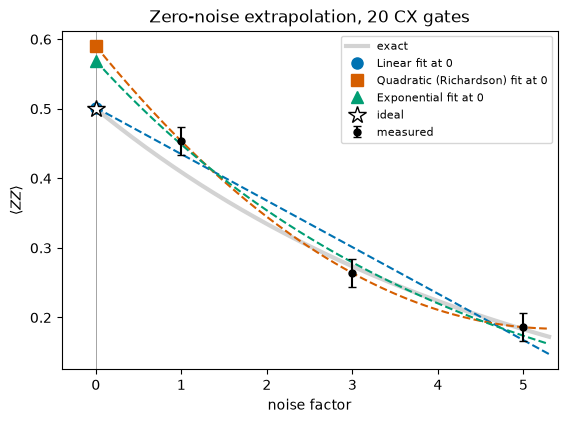

In [11]:
fig = analysis.plot_extrapolation(data, factors=use)

The three fits agree near the data and separate toward $\lambda = 0$. The line undershoots the ideal, because the exact curve bends upward, and the parabola and the exponential land close to it. This is one run, so its distance from the ideal also contains the measurement error.

### Mitigated and unmitigated values together

The table summarizes all repeats. Columns: the mean of the estimate over the repeats, its standard deviation (`std`, the spread), its bias (mean minus ideal, as defined above), and the root-mean-square error (**rmse**): the square root of the average squared distance of one run from the ideal. It is the typical distance of one run from the ideal, and it combines the other two: $\text{rmse}^2 = \text{bias}^2 + \text{std}^2$. (The identity is exact when the standard deviation divides by the number of runs. The table divides by one less, a negligible difference for 500 runs.)

In [12]:
if simulated:
    stats = analysis.print_table(data, use)
else:
    analysis.print_table(data, use)
    print("\nRuntime extrapolators at noise factor 0:", data["runtime"][0])

20 CX gates, noise factors [1, 3, 5], 500 run(s), standard error 0.02 each, ideal 0.5000
                             mean      std     bias     rmse
Unmitigated                0.4101   0.0220  -0.0899   0.0925
Linear                     0.4588   0.0264  -0.0412   0.0489
Quadratic (Richardson)     0.4974   0.0480  -0.0026   0.0481
Exponential                0.5029   0.0364  +0.0029   0.0365


`analysis.plot_estimates` draws every repeated estimate as one dot, grouped by method (horizontal axis), with $\langle ZZ\rangle$ on the vertical axis. The diamond is the mean of the runs, the bar is one standard deviation, and the dashed line is the ideal value.

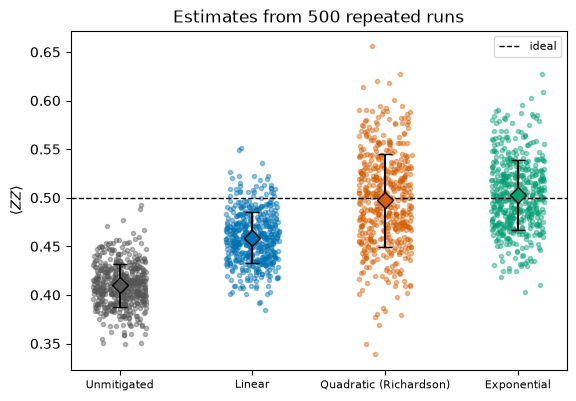

In [13]:
if simulated:
    fig = analysis.plot_estimates(data, use)

The unmitigated estimates are tightly grouped around a value below the ideal. The mitigated ones are centered closer to the ideal and spread more. The exponential is the closest, and the line is the tightest of the three mitigated ones and the farthest from the ideal.

## Stop and think: is the mitigated value closer to the ideal?

1. **Is it closer?** Yes, for all three extrapolators. In the table the unmitigated rmse is about $0.09$, almost all of it bias. The mitigated rmse is about $0.03$ to $0.05$, and it comes from spread and bias together. The exponential has the smallest rmse here.
2. **Does the error bar tell the whole story?** No. The unmitigated value has the smallest spread, and its average is far from the ideal, many spreads away. A small spread around a wrong number is the problem we started with. Mitigation lowers the bias and raises the spread.
3. **What would you do with one run and no ideal value?** Compare the extrapolators. If they disagree by more than their spreads, the choice of model matters more than the data. Here they agree to within about two spreads.

### The cost: amplified statistical error

Each measured value $y_i$ has a random error of size $\sigma$ (the `precision`). A mitigated value is a weighted sum of the measured values, $\sum_i c_i y_i$, as the Richardson example showed. The **variance** of a quantity is the square of its standard deviation. For independent errors the variance of a weighted sum is the sum of the variances, each multiplied by its weight squared. The errors of different points are independent, so the variance of the mitigated value is $\sigma^2\sum_i c_i^2$, and its standard deviation is

$$\sigma_{\text{mitigated}} = \sigma\sqrt{\sum_i c_i^2}.$$

The factor $\sqrt{\sum_i c_i^2}$ is the **amplification** of the random error. For a least-squares line or parabola the weights are fixed by the noise factors alone: they are the first row of the matrix that turns the data into the fitted coefficients, and `analysis.weights` computes them. The exponential is not a weighted sum of the data, so we find its spread by repeating the measurement.

**Worked example: amplification for $\lambda = 1, 3, 5$.**

**Problem.** By what factor do the linear and Richardson extrapolations multiply the error of one measurement?

**Solution.**

1. Richardson weights: $\left(\tfrac{15}{8}, -\tfrac{5}{4}, \tfrac{3}{8}\right)$. The sum of squares is $\tfrac{225 + 100 + 9}{64} = 5.22$, so the amplification is $\sqrt{5.22} = 2.28$.
2. Linear least-squares weights: the least-squares line has slope $b = \sum (x_i - \bar x)(y_i - \bar y)/S_{xx}$ and passes through the mean point, so its value at $0$ is $\bar y - b\bar x$. Here $\bar x = 3$ is the mean noise factor, $\bar y$ the mean value, and $S_{xx} = \sum (x_i - \bar x)^2 = 8$. Since $\sum (x_i - \bar x)\bar y = 0$, the slope is $b = \sum (x_i - \bar x)\,y_i/S_{xx}$, and the value at $0$ is $\sum_i c_i y_i$ with $c_i = \tfrac13 - \bar x\,(x_i - \bar x)/S_{xx}$. For $x = (1, 3, 5)$ this is $\left(\tfrac{13}{12}, \tfrac13, -\tfrac{5}{12}\right)$. The sum of squares is $\tfrac{169 + 16 + 25}{144} = 1.46$, so the amplification is $1.21$.

**Check.** The unmitigated value has weight 1 on one point, so an amplification of 1. Both extrapolators are above 1, and the one with more parameters (Richardson) is higher. The code prints the same numbers.

The standard error of a measurement falls as $1/\sqrt S$ with the number of shots $S$. To match the spread of an unmitigated measurement, Richardson needs each measurement to be $2.28$ times more precise, which is $2.28^2 \approx 5.2$ times as many shots at each of three noise factors. The circuits are also longer: noise factors 1, 3, and 5 run $1 + 3 + 5 = 9$ times the gates of one circuit.

In [14]:
sets = [(1, 2, 3), (1, 3, 5), (1, 2, 3, 4, 5)]
print(f"{'noise factors':<16} {'linear':>8} {'quadratic':>10}")
for fs in sets:
    amp = [
        np.sqrt(np.sum(analysis.weights(m, fs) ** 2)) for m in ("linear", "quadratic")
    ]
    print(f"{','.join(map(str, fs)):<16} {amp[0]:>8.2f} {amp[1]:>10.2f}")

noise factors      linear  quadratic
1,2,3                1.53       4.36
1,3,5                1.21       2.28
1,2,3,4,5            1.05       2.14


`analysis.plot_std_vs_precision` plots the standard deviation of each estimate (vertical axis) against `precision` (horizontal axis), for four values of `precision` with 100 repeats each. Dotted lines are the analytic values for the two weighted-sum extrapolators. Both axes are logarithmic. On such axes a straight line of slope 1 means that the quantity on the vertical axis is proportional to the one on the horizontal axis. All lines have slope 1: halving the `precision` halves every spread.

precision   linear  (analytic)  quadratic  (analytic)  exponential
     0.04   0.0487      0.0483     0.0994      0.0914       0.0694
     0.02   0.0233      0.0242     0.0390      0.0457       0.0326
     0.01   0.0114      0.0121     0.0218      0.0228       0.0165
    0.005   0.0055      0.0060     0.0122      0.0114       0.0078


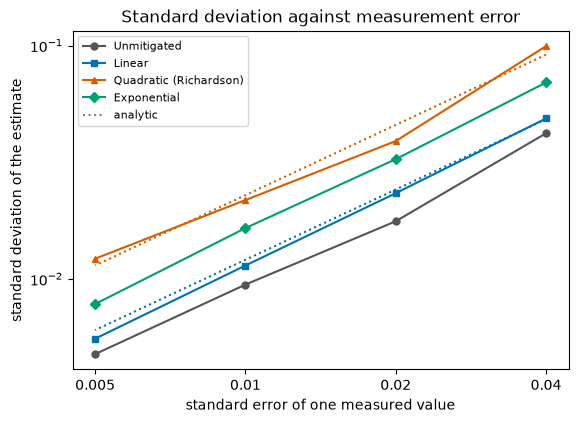

In [15]:
if simulated:
    fig = analysis.plot_std_vs_precision(scan, use)
    print(
        f"{'precision':>9} {'linear':>8} {'(analytic)':>11} {'quadratic':>10} {'(analytic)':>11} {'exponential':>12}"
    )
    for run in scan:
        v = analysis.mitigate(run, use)
        s = {m: v[m][0].std(ddof=1) for m in ops.METHODS}
        a = {
            m: analysis.analytic_std(m, use, run["precision"])
            for m in ("linear", "quadratic")
        }
        print(
            f"{run['precision']:>9} {s['linear']:>8.4f} {a['linear']:>11.4f} {s['quadratic']:>10.4f} "
            f"{a['quadratic']:>11.4f} {s['exponential']:>12.4f}"
        )

The observed spread follows the analytic line to within about 20%. A standard deviation measured from 100 repeats is uncertain by about 7%, and the extrapolators share the same data, so they scatter together. The exponential lies between the line and the parabola. The model with the most parameters (the parabola) has the largest spread.

To reach a Richardson spread of $0.02$ we need $\sigma = 0.02/2.28 = 0.0088$. The run with `precision = 0.01` is 14% above that, and its Richardson spread is about $0.023$, 14% above $0.02$ ($2.28 \times 0.01 = 0.0228$). The two agree.

### Bias against variance

The extrapolators and the noise factors we choose set a trade-off.

- A model with few parameters (the line) has a small spread but cannot follow the curve, so it is biased.
- A model with more parameters (the parabola) can follow the curve and has a larger spread.
- Noise factors closer to $0$ make the extrapolation shorter and the bias smaller. But they sit closer together, so the weights grow and so does the spread.

The table and the figure use the same repeated data, fitted with three sets of noise factors: $(1,2,3)$, $(1,3,5)$, and $(1,2,3,4,5)$. In the figure (`analysis.plot_bias_variance`) the horizontal axis is the standard deviation and the vertical axis is the bias. Color is the extrapolator and the marker shape is the set of noise factors.

noise factors    extrapolator                 bias      std     rmse
1,2,3            Linear                    -0.0226   0.0325   0.0396
1,2,3            Quadratic (Richardson)    -0.0048   0.0905   0.0905
1,2,3            Exponential               +0.0052   0.0436   0.0438
1,3,5            Linear                    -0.0412   0.0264   0.0489
1,3,5            Quadratic (Richardson)    -0.0026   0.0480   0.0481
1,3,5            Exponential               +0.0029   0.0364   0.0365
1,2,3,4,5        Linear                    -0.0450   0.0225   0.0503
1,2,3,4,5        Quadratic (Richardson)    -0.0031   0.0454   0.0455
1,2,3,4,5        Exponential               +0.0036   0.0332   0.0333


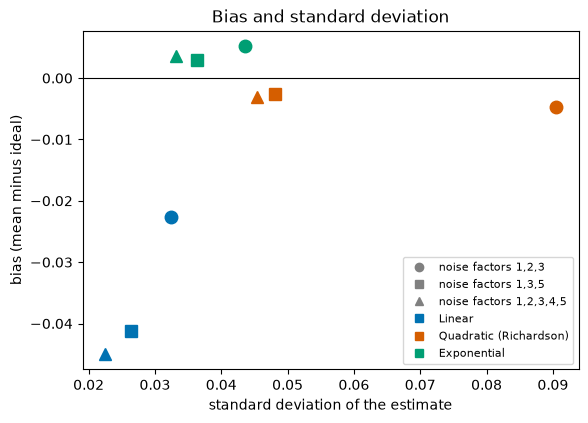

In [16]:
if simulated:
    table = analysis.bias_variance_table(data, sets)
    analysis.print_bias_variance(table)
    fig = analysis.plot_bias_variance(table)

Read the table by rows of the same extrapolator. For the line, moving from $(1,3,5)$ to $(1,2,3)$ cuts the bias by about 40% and raises the spread. For the parabola, the bias is already small at both sets, and the spread nearly doubles for $(1,2,3)$, because the Richardson weights $(3, -3, 1)$ are large. Adding more noise factors, $(1,2,3,4,5)$, lowers the spread of every extrapolator a little, at the price of $1+2+3+4+5 = 15$ times the gates of one circuit instead of $9$. The exponential has almost no bias here for the reason given in Step 1: the simulated noise is exactly exponential. On a device the right model is not known in advance.

### Depth sweep

Last, the circuit length. The longer the circuit, the more noise, and the larger the gap between the unmitigated and the ideal value. `analysis.plot_depth_sweep` shows the mean of 30 repeats (vertical axis: $\langle ZZ\rangle$) against the number of CX gates (horizontal axis), with one standard deviation as the bar, at the noise factors $(1,3,5)$. The table lists, for each method, the mean minus the ideal and the standard deviation in parentheses.

   N          unmitigated               linear            quadratic          exponential
   4     -0.0145 (0.0208)     +0.0030 (0.0256)     +0.0109 (0.0437)     +0.0061 (0.0270)
  10     -0.0443 (0.0207)     -0.0121 (0.0225)     +0.0142 (0.0476)     +0.0024 (0.0263)
  20     -0.0895 (0.0216)     -0.0432 (0.0252)     -0.0012 (0.0499)     -0.0010 (0.0385)
  30     -0.1395 (0.0179)     -0.0922 (0.0207)     -0.0308 (0.0422)     -0.0221 (0.0350)
  40     -0.1598 (0.0287)     -0.1086 (0.0342)     -0.0240 (0.0587)     +0.0184 (0.0649)
(entries are mean minus ideal, with the standard deviation in parentheses)


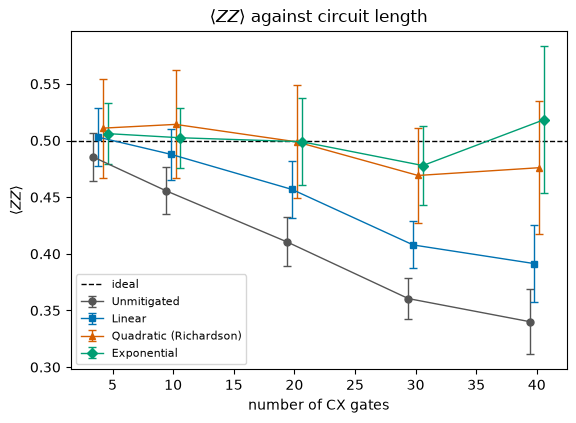

In [17]:
if simulated:
    fig = analysis.plot_depth_sweep(sweep, use)
    values = analysis.mitigate(sweep, use)
    names = ["unmitigated", *ops.METHODS]
    print(f"{'N':>4} " + " ".join(f"{name:>20}" for name in names))
    for k, n in enumerate(sweep["n_cx"]):
        cells = [
            f"{values[m][k].mean() - sweep['ideal']:+.4f} ({values[m][k].std(ddof=1):.4f})"
            for m in names
        ]
        print(f"{n:>4} " + " ".join(f"{c:>20}" for c in cells))
    print("(entries are mean minus ideal, with the standard deviation in parentheses)")

The unmitigated value moves away from the ideal in proportion to the number of gates. The exponential stays within its spread of the ideal at every length, because it has the right model. The parabola stays close to the ideal and drifts below it at the longest circuit, where the curve is farthest from a parabola. The line improves on the unmitigated value but is still biased. The unmitigated spread stays near $0.02$. The mitigated spreads are larger, and they do not shrink as the circuit grows.

## Stop and think: when does ZNE stop working?

1. **What happens when the signal is gone?** At $N = 40$ and $\lambda = 5$ the exact value is about $0.07$, and the standard error of one measurement is $0.02$. As the values fall toward the size of the error, the fits get less reliable, and an exponential fit can return a wild value. Beyond some depth no extrapolation helps, and more shots move that depth only a little.
2. **What if some noise does not grow with the gate count?** The folded circuits do not see it, and ZNE leaves it in. Read-out error is one example. **Drift** is another: the noise of the device changes slowly with time, so circuits run minutes apart sit on different curves.
3. **What if the noise grows faster than the gate count?** Longer circuits also keep each qubit **idle** (waiting for other gates) for longer, and an idle qubit loses signal too. Folded circuits add gate time, so the noise at $\lambda = 5$ can be more than five times the noise at $\lambda = 1$, and the fit model is then wrong.

## Reading the results

The numbers below are for the simulator with the default settings. Noise is random, so a rerun changes the measured ones slightly.

- **The unmitigated value is about $0.41$ and the ideal is $0.50$.** The device loses about 18% of the signal with 20 CX gates at 1% error each. The loss matches the exact value $0.4090$.
- **The mitigated values are closer.** On this run the exponential estimate is about $0.50$ with a spread of about $0.03$, the parabola about $0.49$ with a spread of about $0.05$, and the line about $0.46$ with a spread of about $0.02$.
- **The cost is spread.** The weights amplify the measurement error by $1.2$ (line) and $2.3$ (parabola) for $\lambda = 1, 3, 5$. For $\lambda = 1, 2, 3$ the factors are $1.5$ and $4.4$.
- **Bias and spread trade against each other.** No extrapolator is best on both. The one with the lowest rmse depends on the noise factors and on the true shape of the noise.
- **The exponential has no bias here because we built the noise to be exponential.** On a device, compare the extrapolators. If they disagree, the disagreement is part of the uncertainty.

On hardware, expect some of the following:

- **A curve that is not exponential.** Gate errors are not purely depolarizing, and read-out error lowers the whole curve by a fixed factor.
- **A smaller gain.** The idle time grows with $\lambda$, and the folded circuits are noisier than the model says.
- **Drift between circuits.** Run the noise factors close together in one job, as this code does.
- **One reported value from several extrapolators.** The Runtime Estimator reports as `evs` the value of the first extrapolator in the list that it judges successful. Compare it with the individual values in `evs_extrapolated`.

## What to try next

1. Change `n_cx` to `10` and then to `40`. How do the unmitigated value, the mitigated values, and their spreads change? At which length does ZNE stop paying off?
2. Set `precision = 0.005` and rerun the main experiment. Which spread shrinks by the factor you expect? How many shots per circuit does this correspond to on hardware?
3. Change `use` to `(1, 2, 3)` and then to `(1, 1.5, 2)`. A non-integer factor folds only a fraction of the gates: a factor of 1.5 on 20 gates folds 5 of them once. Noise factors close to 1 give a short extrapolation. What happens to the bias and to the spread?
4. Add a fourth factor, `use = (1, 3, 5, 7)` (also add 7 to `measured`), and compare the quadratic fit with the line. Does the extra point help the parabola?
5. In `ops.py` change the line `SIM_CX_ERROR = 0.01` to `0.03`. Predict the unmitigated value at $N = 20$ from $(1-p)^N\cos\theta$, then check it. Where does the exponential extrapolation start to fail?
6. In `execution.get_primitives` add a read-out error to the noise model: import `ReadoutError` from `qiskit_aer.noise` and add `noise.add_all_qubit_readout_error(ReadoutError([[0.98, 0.02], [0.04, 0.96]]))`. Does ZNE recover the ideal value? Why not?
7. In `execution.run` replace `fold_gates(base, f)` by `fold_circuit(base, int(f))` and set `measured = (1, 3, 5)`. Compare the values with those of gate folding. Why do they agree on the simulator?
8. Run on `ibm_rensselaer` with `qubits = [0, 1]` (check that the qubits are connected). Compare the unmitigated value, `evs_extrapolated` from the Runtime, and the values from our fits. Do the extrapolators agree?

## Terms

| Term | Plain definition | First used |
|---|---|---|
| expectation value $\langle O\rangle$ | Average of the $\pm1$ answer of an observable over many runs | The problem |
| ideal value | Value from a noiseless computer | The problem |
| unmitigated value | Value from the device with no correction | The problem |
| bias | Average of an estimate over repeated runs, minus the ideal value | The problem |
| spread | Standard deviation of an estimate over repeated runs | The problem |
| error mitigation, mitigated value | Methods that estimate the ideal value from noisy runs, and the estimate they give | The problem |
| noise factor $\lambda$ | How much noise a circuit has relative to the original | The problem |
| zero-noise extrapolation | Fit the values at $\lambda > 0$ and read the fit at $\lambda = 0$ | The problem |
| inverse, gate folding | The gate that undoes $G$; replacing $G$ by $G\,G^\dagger\,G$ | The problem |
| Aer, standard error, shots | Qiskit's simulator; typical size of the random error of a value; repetitions of a circuit | Setup |
| depolarizing error | With probability $p$ the state is replaced by a random one | Step 1 |
| decay rate $b$ | The rate in $e^{-b\lambda}$ | Step 1 |
| least squares | Choose the parameters that minimize the sum of squared differences between model and data | Step 1 |
| extrapolator, Richardson extrapolation | A fit model used to extend the data to $\lambda = 0$; the parabola through three points | Step 1 |
| Lagrange form | A polynomial through points written as a weighted sum of the $y$ values | Step 1 |
| read-out error | The device reports the wrong bit when it measures | Step 1 |
| compile, optimization level | Rewrite a circuit for a device; how much the compiler shortens it | Step 2 |
| job, queue | One request to a device; the line of jobs waiting to run | Step 3 |
| IBM Runtime, resilience | IBM's service for running jobs; its name for mitigation options | Step 3 |
| rmse | Square root of the average squared distance of one run from the ideal; $\text{rmse}^2 = \text{bias}^2 + \text{std}^2$ | Step 4 |
| variance, amplification | Square of the standard deviation; factor by which extrapolation multiplies the random error | Step 4 |
| drift, idle | Slow change of device noise with time; a qubit waiting while other gates run | Step 4 |